# 05 · Field extraction with a vision LLM + consistency rules (Phase 5)

**Goal.** Read the printed fields of an ID document (name, dates, numbers, MRZ) into a fixed JSON schema, measure
how accurately that works, and use the fields for deterministic **consistency rules**. A passport's machine-readable
zone (MRZ) repeats the name, number and dates with check digits, so a pasted field that no longer agrees with it
gives the forgery away. That is exactly the Crop_and_Replace case the pixel model of Phase 3B mostly misses.

**Plan.**
1. **Schema and ground truth:** one canonical set of 13 fields, and a mapping from each document type's annotation
   field names to it.
2. **Extractors behind one interface:** Ollama with qwen2.5vl:7b (local "private mode") and a cloud API (only when a
   key is set in `.env`). Both produce structured JSON that is validated with Pydantic and retried on failure.
3. **Evaluation without training:** prompts are iterated only on a **dev set** (3 genuine validation templates per
   type). Once frozen, they run **once** on all 148 genuine **test** templates.
4. **Consistency rules:** first checked on the ground truth of genuine documents (how often do they wrongly flag?),
   then run on forged validation + test templates of the four MRZ document types.
5. **Officer case summary:** an LLM summary restricted to the facts in the input, with a template fallback.

**Re-running this notebook.** Every LLM result is cached per document in `reports/phase5/extractions_*.jsonl`
(`extraction.run_batch`). A re-run loads the cached answers instead of calling the model again, so the one-time test
run is never repeated. The long runs were made with exactly the calls shown here.

Code: `src/ekyc/schemas.py`, `src/ekyc/extraction.py`, `src/ekyc/consistency.py`, `scripts/score_forgery_pages.py`.
Tests: `tests/test_schemas.py`, `tests/test_extraction.py`, `tests/test_consistency.py`.

In [1]:
import json
import os
import re
import subprocess
import sys
import time
from pathlib import Path

import httpx
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pydantic
from IPython.display import display

from ekyc import config, consistency, extraction, schemas

ROOT = config.PROJECT_ROOT
REPORT_DIR = config.REPORTS_DIR / "phase5"
REPORT_DIR.mkdir(parents=True, exist_ok=True)
CACHE = {name: REPORT_DIR / f"extractions_{name}.jsonl" for name in ("dev", "test_genuine", "forged_mrz")}
FORGERY_SCORES_CSV = REPORT_DIR / "forgery_v3_page_scores_valtest.csv"
FORGERY_REVIEW = 0.729  # Phase 3B v3 policy: below = the pixel model lets the page pass
MAX_FALSE_FLAG = 0.05  # a rule that flags more than 5 % of GENUINE documents is demoted to "info"

SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"  # validated colour-blind-safe order; always with a legend


def style(ax, title):
    ax.set_facecolor(SURFACE)
    ax.set_title(title, loc="left", color=INK, fontsize=11)
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.grid(color=GRID, linewidth=0.8, axis="x")
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)
    ax.xaxis.label.set_color(INK_2)
    ax.yaxis.label.set_color(INK_2)


def memory_status():
    swap = subprocess.run(["sysctl", "-n", "vm.swapusage"], capture_output=True, text=True).stdout
    free = subprocess.run(["memory_pressure"], capture_output=True, text=True).stdout.strip().splitlines()[-1]
    swap_gb = float(re.search(r"used = ([\d.]+)M", swap).group(1)) / 1024
    return f"swap used {swap_gb:.1f} GB | {free}"


def peak_memory_gb():
    out = subprocess.run(["footprint", "-p", str(os.getpid())], capture_output=True, text=True).stdout
    value, unit = re.search(r"phys_footprint_peak:\s*([\d.]+)\s*(KB|MB|GB)", out).groups()
    return float(value) / {"KB": 1024 ** 2, "MB": 1024, "GB": 1}[unit]


def summarise_run(results: pd.DataFrame, scores: pd.DataFrame) -> dict:
    """Headline numbers of one extraction run (results: run_batch rows; scores: schemas.score_extractions)."""
    printed = scores[~scores["spurious"]]
    return {"documents": len(results), "JSON valid": results["valid"].mean(),
            "retries (total)": int(results["retries"].sum()), "latency p50 (s)": results["latency_s"].median(),
            "latency p95 (s)": results["latency_s"].quantile(0.95),
            "input tokens (mean)": results["input_tokens"].mean(), "output tokens (mean)": results["output_tokens"].mean(),
            "fields compared": len(printed), "exact match": printed["exact"].mean(),
            "normalized match": printed["normalized"].mean(), "CER (mean)": printed["cer"].mean(),
            "spurious fields": int(scores["spurious"].sum())}


notebook_start = time.perf_counter()
print(f"pydantic {pydantic.__version__} | httpx {httpx.__version__} | prompt version {extraction.PROMPT_VERSION}")
print("memory:", memory_status())

pydantic 2.14.3 | httpx 0.28.1 | prompt version v2
memory: swap used 12.8 GB | System-wide memory free percentage: 66%


<!-- id: setup -->
**Setup.** Pydantic 2.14 validates the answers; httpx makes the HTTP calls to Ollama (and to a cloud API if one is
configured). The prompts are version **v2**, frozen after the dev set (section 3).

This run of the notebook loads every extraction from the caches, so the model was not loaded and memory was mostly
free (65 %). During the long one-time runs it was much tighter (9-13 % free), which shows in the latencies in
section 4.

## 1 · Schema and ground truth

In [2]:
fields_gt = pd.read_csv(config.FIELDS_GT_CSV)
fields_gt["doc_type"] = fields_gt["doc_id"].str.rsplit("_", n=1).str[0]
inventory = fields_gt.groupby("doc_type").agg(documents=("doc_id", "nunique"),
                                               field_names=("field_name", lambda s: ", ".join(sorted(s.dropna().unique()))))
print("annotation boxes without a field name (skipped, Phase 2 finding):", int(fields_gt["field_name"].isna().sum()))
pd.set_option("display.max_colwidth", 200)
display(inventory)

annotation boxes without a field name (skipped, Phase 2 finding): 1


,documents,field_names
doc_type,,
alb_id,100,"authority, birth_date, birth_place, expiry_date, face, gender, id_number, issue_date, name, nationality, number, photo, signature, surname"
aze_passport,100,"authority, authority_eng, birth_date, birth_place, code, expiry_date, expiry_date_2, face, gender, id_number, issue_date, mrz_line0, mrz_line1, name, name_eng, nationality/nationality_eng, number,..."
esp_id,100,"birth_date, expiry_date, face, gender, id_number, issue_date, name, name_code, nationality, number, photo, signature, surname, surname_second"
est_id,100,"birth_date, expiry_date, face, gender, id_number, name, nationality, number, number2, number3, photo, signature, surname"
fin_id,100,"birth_date, birth_date_2, birth_date_22, code, expiry_date, face, gender, issue_date, name, nationality, number, photo, signature, surname"
grc_passport,100,"authority, birth_country, birth_date, birth_place, birth_place_eng, code, expiry_date, face, gender, height, issue_date, mrz_line0, mrz_line1, name, name_eng, nationality, number, photo, surname, ..."
lva_passport,100,"authority_line0, authority_line1, birth_date, birth_place, code, expiry_date, face, gender, height, id_number, issue_date, mrz_line0, mrz_line1, name, nationality, number, photo, signature, surnam..."
rus_internalpassport,100,"birth_date, birth_place_line0, birth_place_line1, birth_place_line2, face, gender, name, number, patronymic, photo, surname"
srb_passport,100,"authority, birth_date, birth_place, code, expiry_date, expiry_date2, face, gender, id_number, issue_date, mrz_line0, mrz_line1, name, nationality, number, photo, residence_line0, residence_line1, ..."


<!-- id: inventory -->
**Annotated fields per document type.** Each type has 100 genuine templates, and each type uses its own field names.
- Some fields hold the same value twice (`number2`, `number3`, `expiry_date_2`).
- Some hold only part of a value (`fin_id`: `birth_date_2` + `code` form the personal identity code).
- Some hold a second spelling of the same name (`surname_eng`, `name_eng`).

One annotation box has no field name (`aze_passport_03`, already known from Phase 2) and is skipped.

In [3]:
mapping = schemas.mapping_table()
display(mapping.style.map(lambda v: "color: #898781" if v == "-" else ""))
mapping.to_csv(REPORT_DIR / "field_mapping.csv")
print("canonical fields:", ", ".join(schemas.CANONICAL_FIELDS))
print("annotation fields not mapped:", ", ".join(sorted(schemas.UNMAPPED_FIELDS)))

,surname,given_names,birth_date,gender,nationality,document_number,personal_number,issue_date,expiry_date,birth_place,authority,mrz_line0,mrz_line1
alb_id,surname,name,birth_date,gender,nationality,number,id_number,issue_date,expiry_date,birth_place,authority,-,-
aze_passport,surname_eng,name_eng,birth_date,gender,nationality/nationality_eng,number,id_number,issue_date,expiry_date,birth_place,authority,mrz_line0,mrz_line1
esp_id,surname + surname_second,name,birth_date,gender,nationality,id_number,number,issue_date,expiry_date,-,-,-,-
est_id,surname,name,birth_date,gender,nationality,number,id_number,-,expiry_date,-,-,-,-
fin_id,surname,name,birth_date,gender,nationality,number,birth_date_2 + code,issue_date,expiry_date,-,-,-,-
grc_passport,surname_eng,name_eng,birth_date,gender,nationality,number,-,issue_date,expiry_date,birth_place_eng,authority,mrz_line0,mrz_line1
lva_passport,surname,name,birth_date,gender,nationality,number,id_number,issue_date,expiry_date,birth_place,authority_line0 + authority_line1,mrz_line0,mrz_line1
rus_internalpassport,surname,name + patronymic,birth_date,gender,-,number,-,-,-,birth_place_line0 + birth_place_line1 + birth_place_line2,-,-,-
srb_passport,surname,name,birth_date,gender,nationality,number,id_number,issue_date,expiry_date,birth_place,authority,mrz_line0,mrz_line1
svk_id,surname,name,birth_date,gender,nationality,number,id_number,issue_date,expiry_date,-,issue_place,-,-


canonical fields: surname, given_names, birth_date, gender, nationality, document_number, personal_number, issue_date, expiry_date, birth_place, authority, mrz_line0, mrz_line1
annotation fields not mapped: authority_eng, birth_country, birth_date_22, birth_place (grc: Greek form), code, expiry_date2, expiry_date_2, face, height, name (aze, grc: national form), name_code, number2, number3, photo, residence_line0, residence_line1, signature, surname (aze, grc: national form), type


<!-- id: mapping -->
**The mapping to the 13 canonical fields** (`-` = not printed on that type). The non-obvious decisions:
- **`number` vs `id_number` changes meaning between types.** On `esp_id`, `number` is the holder's DNI (personal
  number) and `id_number` is the card's own number (IDESP), the opposite of `alb_id`. This is the label swap seen in
  the Phase 1 smoke test, and the mapping (and the prompt) make it explicit.
- **`aze_passport` and `grc_passport` print every name twice**, in the national form and as a Latin
  transliteration. The canonical names are the Latin lines (`*_eng`), because those are what the MRZ encodes.
  Azerbaijani has no single transliteration (Ğ -> G or GH), so transliterating the national form ourselves would not
  match.
- **Parts are joined:** two Spanish surnames; Russian first name + patronymic; Latvian authority lines; Russian
  birth-place lines. The Finnish personal code = birth date as DDMMYY + `code` (e.g. `010481-927N`).
- **Not mapped:** duplicates, layout codes (`type`, `code`), and fields outside the schema (height, residence,
  photo, signature).

In [4]:
truth = schemas.ground_truth_table(fields_gt)  # canonical ground truth of all 1,000 genuine templates
present = truth.groupby("doc_type")[list(schemas.CANONICAL_FIELDS)].count()
display(present)
for f in schemas.DATE_FIELDS:
    values = truth[f].dropna()
    print(f"{f}: {values.map(lambda v: schemas.parse_date(v, f) is not None).sum()} of {len(values)} printed dates parse "
          f"(formats: {', '.join(sorted(values.str.replace(r'[0-9]', '9', regex=True).str.replace(r'[A-Za-z]', 'a', regex=True).unique()))})")
print("gender after normalisation:", truth["gender"].map(schemas.normalize_gender).value_counts().to_dict())
display(pd.DataFrame({"printed": ["02 Jan 87", "140915", "Ž / F", "45    98 647461", "Α.Ε.Α."],
                      "field": ["birth_date", "issue_date", "gender", "document_number", "authority"]})
        .assign(normalized=lambda d: [schemas.normalize_value(f, v) for f, v in zip(d["field"], d["printed"])]))

,surname,given_names,birth_date,gender,nationality,document_number,personal_number,issue_date,expiry_date,birth_place,authority,mrz_line0,mrz_line1
doc_type,,,,,,,,,,,,,
alb_id,100,100,100,100,100,100,100,100,100,100,100,0,0
aze_passport,100,100,100,100,100,100,100,100,100,100,100,100,100
esp_id,100,100,100,100,100,100,100,100,100,0,0,0,0
est_id,100,100,100,100,100,100,100,0,100,0,0,0,0
fin_id,100,100,100,100,100,100,100,100,100,0,0,0,0
grc_passport,100,100,100,100,100,100,0,100,100,100,100,100,100
lva_passport,100,100,100,100,100,99,100,100,100,100,100,100,100
rus_internalpassport,100,100,100,100,0,100,0,0,0,100,0,0,0
srb_passport,100,100,100,100,100,100,100,100,100,100,100,100,100


birth_date: 1000 of 1000 printed dates parse (formats: 99 99 9999, 99 aaa 99, 99-99-9999, 99. 99. 9999, 99.99.9999, 99.99.9999.)
issue_date: 800 of 800 printed dates parse (formats: 99 aaa 99, 99-99-9999, 99. 99. 9999, 99.99.9999, 99.99.9999., 999999)
expiry_date: 900 of 900 printed dates parse (formats: 99 99 9999, 99 aaa 99, 99-99-9999, 99. 99. 9999, 99.99.9999, 99.99.9999.)
gender after normalisation: {'M': 500, 'F': 500}


,printed,field,normalized
0,02 Jan 87,birth_date,1987-01-02
1,140915,issue_date,2015-09-14
2,Ž / F,gender,F
3,45 98 647461,document_number,4598647461
4,Α.Ε.Α.,authority,a.e.a.


<!-- id: truth -->
**Canonical ground truth of the 1,000 genuine templates.**
- The counts per type match the mapping: MRZ lines only on the four passports with one; no issue/expiry date on
  the Russian internal passport; no issue date on `est_id`.
- **All 2,700 printed dates parse**, across 10 formats: `20-11-1991`, `14.08.1994`, `28.09.1974.`,
  `01. 04. 1981`, `31 01 1971`, `02 Jan 87` (two-digit year), `13 Okt 74`, and the compact `140915` (DDMMYY).
  Two-digit years get a century by field: expiry dates are in the 2000s; birth and issue dates in the 2000s only if
  not in the future.
- **Gender normalises to exactly 500 M and 500 F.**

How the comparison treats a value (the table shows examples):
- **exact match:** identical after trimming the ends;
- **normalized match:**
  - dates in ISO, gender as M/F, and numbers without spaces;
  - case and spacing ignored (also around punctuation);
  - Greek/Cyrillic capitals that look like Latin ones count as the same letter (the image cannot tell them apart);
  - the first MRZ line ignores how many trailing `<` fillers there are.
- **Diacritics are never ignored:** Mikuš and Mikus are different spellings.

## 2 · Extractors

In [5]:
print(extraction.build_prompt("esp_id"))
print("\nJSON schema keys:", list(extraction.json_schema()["properties"]))
ollama = extraction.OllamaExtractor()
cloud = extraction.CloudExtractor.from_env()
EXTRACTORS = {"ollama": ollama} | ({"cloud": cloud} if cloud else {})
print(f"\nOllama {ollama.model}: {'available' if ollama.available() else 'NOT available'} (keep_alive {ollama.keep_alive}, "
      f"num_ctx {ollama.num_ctx}, temperature 0)")
print("Cloud:", f"{cloud.provider} / {cloud.model}" if cloud else
      "skipped: no LLM_API_KEY in .env (see .env.example); only the local model runs")

This image is a Spanish identity card (DNI). Return a JSON object with these keys.

Fields printed on this document (where to find them):
- surname: 'PRIMER APELLIDO' and 'SEGUNDO APELLIDO' joined with one space
- given_names: 'NOMBRE'
- birth_date: 'FECHA DE NACIMIENTO'
- gender: 'SEXO'
- nationality: 'NACIONALIDAD'
- document_number: 'IDESP': 3 letters and 6 digits (this is NOT the DNI number)
- personal_number: 'DNI NÚM.' at the bottom left: 8 digits and a letter
- issue_date: the 6-digit date (DDMMYY) printed on the left, below the chip
- expiry_date: 'VÁLIDO HASTA'

Not printed on this document, always null: birth_place, authority, mrz_line0, mrz_line1

Rules: copy each value exactly as printed, keeping letter case, every diacritic (such as č, ć, ë, ā, ş) and the date format (do not translate, transliterate or reformat). Give the value only, without its label. If a value is unreadable, use null.

JSON schema keys: ['surname', 'given_names', 'birth_date', 'gender', 'nationality', '

<!-- id: extractors -->
**Extractors.** The prompt is built per document type (in the pipeline the type comes from the Phase 3A
classifier). It names each field by its printed label and gives the number formats, to prevent the label swaps.
Fields this type does not print are listed as always null.

The answer is forced into the schema:
- Ollama's `format` is set to the JSON schema of `IDFields`, so the model can only produce text that fits it.
- The answer is then validated with Pydantic. On a validation error the model gets the error message and tries
  again, at most twice.

**Cloud path:** skipped. There is no `.env` with `LLM_API_KEY`; `.env.example` shows the three settings
(`LLM_PROVIDER` = anthropic or openai, `LLM_MODEL`, `LLM_API_KEY`). The cloud extractor is covered by tests with
simulated API responses, so it is ready but unmeasured.

In [6]:
# Memory before the local model: qwen2.5vl:7b needs about 6-8 GB while loaded (Phase 1 measurement).
tags = httpx.get(f"{ollama.host}/api/tags", timeout=5).json()["models"]
size = next(m["size"] for m in tags if m["name"] == ollama.model)
loaded = [m["name"] for m in httpx.get(f"{ollama.host}/api/ps", timeout=5).json().get("models", [])]
print(f"{ollama.model}: {size / 1e9:.1f} GB on disk; loaded now: {loaded or 'nothing'}")
print("memory:", memory_status())

qwen2.5vl:7b: 6.0 GB on disk; loaded now: nothing
memory: swap used 12.8 GB | System-wide memory free percentage: 66%


<!-- id: memory -->
**Memory check before the model.** qwen2.5vl:7b is 6.0 GB on disk and needs about 6-8 GB of RAM while loaded.
Nothing was loaded when this cell ran.

During the one-time runs, the 16 GB machine had only 9-13 % free and Ollama's runner process grew steadily. Its
log shows a prompt cache with an 8 GB limit, which fills up with a different image every request. The run was
watched, and the model was unloaded (keep_alive 0) whenever the runner passed 8 GB: three times automatically, once
by hand. Every request in progress finished first, so no answer was lost.

## 3 · Dev set: prompt iteration (3 genuine validation templates per type)

In [7]:
manifest = pd.read_csv(config.MANIFEST_CSV)
dev_docs = extraction.template_documents(manifest, ("val",), 0, per_type=3)
dev_now = extraction.run_batch(dev_docs, ollama, CACHE["dev"])  # cached: prompt versions v1 and v2 were run once each
history = pd.DataFrame([json.loads(line) for line in CACHE["dev"].read_text().splitlines()])
dev_runs = {v: history[history["prompt_version"] == v].set_index("doc_id").loc[dev_docs["doc_id"]].reset_index()
            for v in sorted(history["prompt_version"].unique())}
dev_scores = {v: schemas.score_extractions(r, truth) for v, r in dev_runs.items()}
display(pd.DataFrame({f"prompt {v}": summarise_run(dev_runs[v], dev_scores[v]) for v in dev_runs}).round(3))
by_field = pd.DataFrame({f"{v} normalized": s.groupby("field")["normalized"].mean() for v, s in dev_scores.items()})
display(by_field.reindex(schemas.CANONICAL_FIELDS).round(3))

,prompt v1,prompt v2
documents,30.000,30.000
JSON valid,1.000,1.000
retries (total),0.000,0.000
latency p50 (s),18.080,12.750
latency p95 (s),28.117,22.268
input tokens (mean),1725.400,1748.700
output tokens (mean),162.600,163.333
fields compared,312.000,312.000
exact match,0.843,0.856
normalized match,0.962,0.968


,v1 normalized,v2 normalized
field,,
surname,0.900,0.867
given_names,0.967,0.967
birth_date,1.000,1.000
gender,1.000,1.000
nationality,1.000,1.000
document_number,0.900,1.000
personal_number,1.000,1.000
issue_date,1.000,1.000
expiry_date,1.000,1.000


<!-- id: dev -->
**Dev set: prompt v1 against v2** (the same 30 genuine validation templates, 312 printed fields).

| | v1 | v2 |
|---|---|---|
| valid JSON / retries | 100 % / 0 | 100 % / 0 |
| exact / normalized match | 84.3 % / 96.2 % | 85.6 % / **96.8 %** |
| mean CER | 1.6 % | **0.5 %** |
| latency p50 | 18.1 s | 12.8 s |

What v2 changed, after reading v1's errors:
- **`aze_passport`:** take the passport number from the top right, not the 2-letter type code `PC` (v1 returned
  `PC` on all three Azerbaijani passports). `document_number` went from 90 % to 100 %.
- **Greek and Azerbaijani names, Greek birth place:** copy the printed LATIN line exactly and never transliterate.
  `birth_place` went from 94 % to 100 %.
- **Diacritics:** the rule now names examples (č, ć, ë, ā, ş).

Two fields dropped by one document each (`surname`, `mrz_line0`): small changes at temperature 0. One iteration
was enough. The remaining errors are character-level reading limits that more prompt tuning on 30 documents
would only overfit, so v2 was frozen here.

In [8]:
current = dev_scores[extraction.PROMPT_VERSION]
wrong = current[~current["normalized"] & ~current["spurious"]]
print(f"prompt {extraction.PROMPT_VERSION}: {len(wrong)} of {len(current)} printed fields not matched on the dev set")
display(wrong[["doc_id", "field", "truth", "predicted", "cer"]].round(3))

prompt v2: 10 of 312 printed fields not matched on the dev set


,doc_id,field,truth,predicted,cer
1,alb_id_06,given_names,Afërdita,Aferdita,0.125
44,aze_passport_11,mrz_line0,PCAZEALLAHVERDIYEV<<AGAKHAN<<<<<<<<<<<<<<<<<,PCAZEALLAHVERDIYEV<<<<<<AGAKHAN<<<<<<<<<<<<<<<<,0.148
45,aze_passport_11,mrz_line1,C205768684AZE8007083M2702124C861R2B<<<<<<<14,C205768684AZE8007083M2702124C861R2B<<<<<<<<14,0.023
57,aze_passport_14,mrz_line0,PCAZEARTUR<<AGHASAF<<<<<<<<<<<<<<<<<<<<<<<<<,PCAZEARTUR<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<,0.474
58,aze_passport_14,mrz_line1,C516653213AZE8705105M280620648V8R2J<<<<<<<50,C516653213AZE8705105M280620648V8R2J<<<<<<<<50,0.023
71,aze_passport_20,mrz_line1,C293540870AZE9211041M241212629E76QG<<<<<<<04,C293540870AZE9211041M241212629E76QG<<<<<<<<04,0.023
174,grc_passport_05,surname,ALEXANDER,ALEXANDROU,0.333
212,lva_passport_19,surname,KALNIŅŠ,KALNĪŅŠ,0.143
292,svk_id_11,surname,Ćesko,Česko,0.200
302,svk_id_19,surname,Hrenić,Hrenič,0.167


<!-- id: dev_errors -->
**What v2 still gets wrong on the dev set (10 of 312 fields).**
- **MRZ filler counts:** on Azerbaijani passports the second MRZ line always gets one `<` too many, and the first
  line sometimes too many fillers or a dropped given name. Long runs of identical characters are hard for the model
  to count. The consistency rules repair the filler count in line 2 (section 5); a dropped name cannot be repaired.
- **Diacritics:** ć/č (`Hrenić` -> `Hrenič`), Ņ/Ī (`KALNIŅŠ` -> `KALNĪŅŠ`), ë dropped (`Afërdita` -> `Aferdita`).
  At 1280 px these marks are a few pixels.
- **One transliteration:** `ALEXANDER` -> `ALEXANDROU`. The model transliterated the Greek line
  (ΑΛΕΞΑΝΔΡΟΥ) instead of copying the Latin one, despite the instruction.

## 4 · Final set (run once, prompts frozen): all 148 genuine test templates

The prompts were frozen after the dev set (`PROMPT_VERSION = "v2"`), and this run was made once. With an API key in
`.env`, the cloud model would run on the same 148 documents and appear as a second column.

In [9]:
test_docs = extraction.template_documents(manifest, ("test",), 0)
test_runs = {name: extraction.run_batch(test_docs, ex, CACHE["test_genuine"]) for name, ex in EXTRACTORS.items()}
test_scores = {name: schemas.score_extractions(r, truth) for name, r in test_runs.items()}
side_by_side = pd.DataFrame({f"{name} ({EXTRACTORS[name].model})": summarise_run(test_runs[name], test_scores[name])
                             for name in test_runs})
if "cloud" not in test_runs:
    side_by_side["cloud"] = "not run: no API key"
display(side_by_side)

,ollama (qwen2.5vl:7b),cloud
documents,148.000000,not run: no API key
JSON valid,0.993243,not run: no API key
retries (total),0.000000,not run: no API key
latency p50 (s),31.586417,not run: no API key
latency p95 (s),64.111870,not run: no API key
input tokens (mean),1749.748299,not run: no API key
output tokens (mean),163.659864,not run: no API key
fields compared,1547.000000,not run: no API key
exact match,0.840983,not run: no API key
normalized match,0.952165,not run: no API key


<!-- id: test_summary -->
**Final run on the 148 genuine test templates (once, prompt v2, Ollama qwen2.5vl:7b).**
- **JSON validity 99.3 % (147 of 148), no retries needed.** The one failure, `lva_passport_62`, is not a JSON
  error. The model got stuck repeating one token (almost certainly the long `<` filler run of the MRZ), and Ollama
  aborted it ("token repeat limit reached"). It happened again at temperature 0 when the document was sent a second
  time. It counts as a failed extraction, with all 13 of its fields wrong. In the pipeline this means "extraction
  failed -> manual review".
- **Accuracy over all 1,547 printed fields:** exact **84.1 %**, normalized **95.2 %**, mean CER **1.8 %**. No field
  was filled that the document does not print (0 spurious).
- **Latency:** p50 31.6 s, p95 64.1 s, about 2.5x the dev run (12.8 s), because the machine was swapping heavily
  during this run. On a free machine expect about 13 s per document.
- **Tokens:** about 1,750 in per document (≈1,300 of them the 1280 px image) and 164 out.
- **Cloud:** not run (no API key), so there is no side-by-side comparison.

In [10]:
scores = test_scores["ollama"]
printed = scores[~scores["spurious"]]
per_field = printed.groupby("field").agg(documents=("doc_id", "size"), exact=("exact", "mean"),
                                         normalized=("normalized", "mean"), cer=("cer", "mean"))
per_field = per_field.reindex([f for f in schemas.CANONICAL_FIELDS if f in per_field.index])
per_type = printed.groupby("doc_type").agg(fields=("doc_id", "size"), exact=("exact", "mean"),
                                           normalized=("normalized", "mean"), cer=("cer", "mean"))
per_type["documents fully correct"] = printed.groupby(["doc_type", "doc_id"])["normalized"].all().groupby("doc_type").mean()
display(per_field.round(3))
display(per_type.round(3))
per_field.to_csv(REPORT_DIR / "extraction_test_per_field.csv")
per_type.to_csv(REPORT_DIR / "extraction_test_per_doc_type.csv")
scores.to_csv(REPORT_DIR / "extraction_test_per_document_field.csv", index=False)
test_runs["ollama"].drop(columns=["raw"]).to_csv(REPORT_DIR / "extraction_test_per_document.csv", index=False)

,documents,exact,normalized,cer
field,,,,
surname,148,0.905,0.919,0.020
given_names,148,0.912,0.926,0.063
birth_date,148,0.892,0.986,0.007
gender,148,0.939,0.993,0.007
nationality,134,0.858,0.993,0.007
document_number,148,0.892,0.986,0.008
personal_number,120,0.983,0.983,0.017
issue_date,119,0.874,0.992,0.008
expiry_date,134,0.881,0.993,0.007


,fields,exact,normalized,cer,documents fully correct
doc_type,,,,,
alb_id,176,0.989,0.989,0.006,0.875
aze_passport,234,0.667,0.859,0.032,0.000
esp_id,135,0.978,0.985,0.001,0.867
est_id,120,1.000,1.000,0.000,1.000
fin_id,126,0.635,1.000,0.000,1.000
grc_passport,168,0.792,0.935,0.027,0.429
lva_passport,182,0.786,0.890,0.075,0.500
rus_internalpassport,84,0.833,1.000,0.000,1.000
srb_passport,182,0.857,0.984,0.002,0.786


<!-- id: test_tables -->
**Per field and per document type (normalized match; the failed document counts as wrong everywhere).**
- **Dates, gender, nationality and both numbers: 98-99 %.** The number trap is solved: `document_number` 98.6 % and
  `personal_number` 98.3 %. The esp_id swap of v1's smoke test does not occur. The two misses: `AKO055707` read as
  `AK0055707` (letter O vs zero), and one Albanian personal number that came back as a completely different value.
- **Names: about 92-93 %.** The errors are diacritics and the two-line names of the Greek and Azerbaijani passports.
- **MRZ: line 1 76.7 %, line 2 65.0 %.** Mostly filler miscounts.
- **By type:** `est_id`, `fin_id` and `rus_internalpassport` at 100 %; `alb_id`, `esp_id`, `srb_passport` and
  `svk_id` at 98-99 %; `grc_passport` 93.5 %, `lva_passport` 89.0 % (including the failed document) and
  `aze_passport` 85.9 % (its MRZ).
- **Exact vs normalized:** the large gap on `fin_id` (63.5 % vs 100 %) is formatting only. The card prints
  `01. 08. 1998` and the model writes `01.08.1998`. Gaps like this are why both measures are reported.

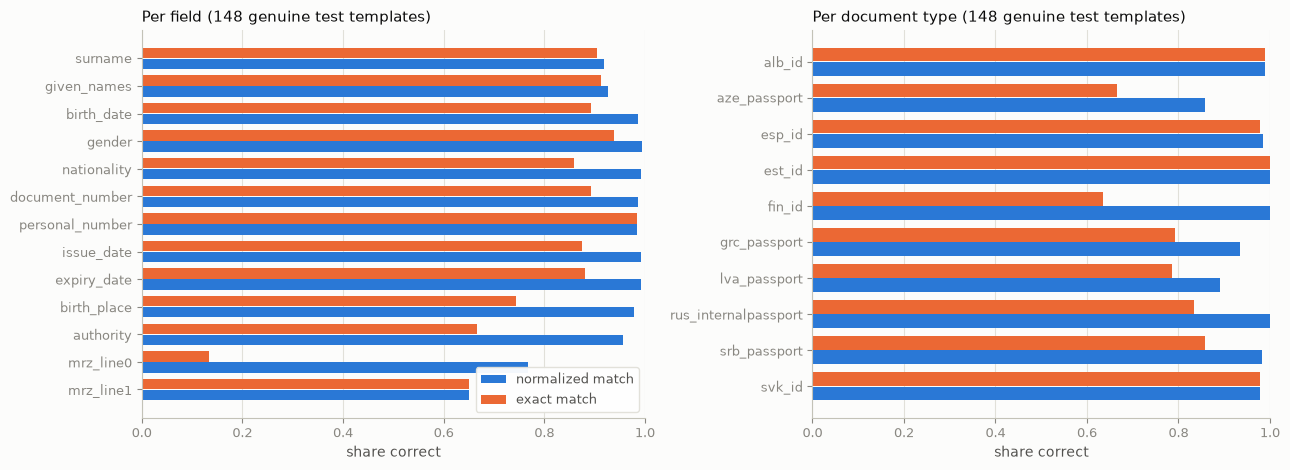

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), dpi=100, facecolor=SURFACE, gridspec_kw={"width_ratios": [1.1, 1]})
for ax, table, title in ((axes[0], per_field, "Per field"), (axes[1], per_type, "Per document type")):
    y = np.arange(len(table))
    ax.barh(y + 0.2, table["normalized"], height=0.38, color=BLUE, label="normalized match")
    ax.barh(y - 0.2, table["exact"], height=0.38, color=ORANGE, label="exact match")
    ax.set_yticks(y, table.index)
    ax.invert_yaxis()
    ax.set_xlim(0, 1.0)
    style(ax, f"{title} (148 genuine test templates)")
    ax.set_xlabel("share correct")
axes[0].legend(frameon=True, framealpha=0.95, edgecolor=GRID, labelcolor=INK_2, fontsize=9, loc="lower right")
fig.tight_layout()
fig.savefig(REPORT_DIR / "extraction_test_accuracy.png", dpi=150, facecolor=SURFACE, bbox_inches="tight")
plt.show()

<!-- id: test_figure -->
**Figure.** Blue = normalized match, orange = exact match. The two MRZ lines are the clear weak spot, and the gap
between the bars on dates, nationality and birth place is formatting (spaces, case), not reading errors. On the
right, the passports with an MRZ (aze, grc, lva) and the Azerbaijani names pull their types down; the ID cards
without an MRZ are read almost perfectly.

In [12]:
wrong = printed[~printed["normalized"]].copy()
wrong["kind"] = np.select([wrong["predicted"].isna(), wrong["cer"] <= 0.2], ["missing", "small (CER <= 0.2)"], "large")
print(f"{len(wrong)} of {len(printed)} printed fields not matched after normalisation:")
display(wrong.groupby(["field", "kind"]).size().unstack(fill_value=0))
display(wrong.sort_values("cer", ascending=False).head(12)[["doc_id", "field", "truth", "predicted", "cer"]].round(3))

74 of 1547 printed fields not matched after normalisation:


kind,large,missing,small (CER <= 0.2)
field,,,
authority,0,1,3
birth_date,0,1,1
birth_place,0,1,1
document_number,0,1,1
expiry_date,0,1,0
gender,0,1,0
given_names,8,1,2
issue_date,0,1,0
mrz_line0,7,1,6


,doc_id,field,truth,predicted,cer
320,aze_passport_75,given_names,FAMILA,FAMILƏ ELVIN QIZI,2.000
359,aze_passport_86,given_names,FERGANA,BAHADIR QIZI,1.571
912,grc_passport_87,given_names,CATHERINE,AIKATEPINH CATHERINE,1.222
900,grc_passport_76,given_names,MARIA,MAPIA MARIA,1.200
948,grc_passport_97,given_names,MIRANDA,MIPANTA MIRANDA,1.143
1076,lva_passport_62,surname,ZVIRGZDIŅŠ,None,1.000
1077,lva_passport_62,given_names,KONSTANTĪNS,None,1.000
1078,lva_passport_62,birth_date,07.07.1975.,None,1.000
1079,lva_passport_62,gender,V/M,None,1.000
1080,lva_passport_62,nationality,LATVIJAS,None,1.000


<!-- id: test_errors -->
**The 74 unmatched fields, by kind.**
- **13 are the failed document** (every field missing).
- **MRZ line 2: 20, all small.** One `<` too many on Azerbaijani passports.
- **MRZ line 1: 7 large** (given name dropped from the name field) **and 6 small** (filler counts, single letters).
- **Given names: 8 large.** The model copied the national line, or both lines:
  - `FAMILƏ ELVIN QIZI` for `FAMILA`;
  - Greek letters read as look-alike Latin ones (`MAPIA MARIA` for `MARIA`).
- **Surnames: 8 small.** Diacritics, and `BAĞIRZADE` copied from the national line instead of `BAGIRZADE`.
- **One personal number** is a different value altogether, the only "large" error on a number field.

## 5 · Consistency rules

In [13]:
gt_rules = consistency.rules_table(truth)  # the rules on the GROUND TRUTH of all 1,000 genuine documents
applied = gt_rules[gt_rules["status"] != "skip"]
rule_rates = applied.groupby("rule").agg(documents=("status", "size"), false_flags=("status", lambda s: (s == "fail").sum()))
rule_rates["false-flag rate"] = rule_rates["false_flags"] / rule_rates["documents"]
by_type = applied.assign(fail=applied["status"] == "fail").groupby(["rule", "doc_type"])["fail"].mean()
rule_rates["worst document type"] = by_type.groupby("rule").max()
rule_rates = rule_rates.reindex(list(consistency.RULES))
demote = rule_rates.index[(rule_rates["false-flag rate"] > MAX_FALSE_FLAG) | (rule_rates["worst document type"] > MAX_FALSE_FLAG)]
for rule in demote:  # applied to every later run in this notebook
    consistency.RULE_LEVEL_OVERRIDES[(rule, "*")] = "info"
rule_rates["level"] = ["info" if r in demote else "flag" for r in rule_rates.index]
display(rule_rates.round(4))
print("rules demoted to info:", list(demote) or "none")
print("\ngenuine documents the rules flag (inconsistencies inside the dataset itself):")
display(applied[applied["status"] == "fail"][["doc_id", "rule", "detail"]])
rule_rates.to_csv(REPORT_DIR / "rules_false_flags_ground_truth.csv")

,documents,false_flags,false-flag rate,worst document type,level
rule,,,,,
mrz_format,400,0,0.0000,0.00,flag
mrz_check_document_number,400,0,0.0000,0.00,flag
mrz_check_birth_date,400,0,0.0000,0.00,flag
mrz_check_expiry_date,400,0,0.0000,0.00,flag
mrz_check_composite,400,0,0.0000,0.00,flag
mrz_vs_surname,400,3,0.0075,0.03,flag
mrz_vs_given_names,400,0,0.0000,0.00,flag
mrz_vs_birth_date,400,3,0.0075,0.03,flag
mrz_vs_document_number,399,0,0.0000,0.00,flag


rules demoted to info: none

genuine documents the rules flag (inconsistencies inside the dataset itself):


,doc_id,rule,detail
1325,aze_passport_10,mrz_vs_surname,page 'ALEKSEYEV' vs MRZ 'ALEXSEYEV'
1555,aze_passport_29,mrz_vs_birth_date,page 1979-12-01 vs MRZ 1977-09-23
1591,aze_passport_32,mrz_vs_birth_date,page 1979-12-01 vs MRZ 1976-04-14
1793,aze_passport_49,mrz_vs_surname,page 'ALEKSEYEVA' vs MRZ 'ALEXSEYEVA'
1963,aze_passport_63,mrz_vs_birth_date,page 1979-12-01 vs MRZ 2002-10-12
2057,aze_passport_71,mrz_vs_surname,page 'AFANADIYEV' vs MRZ 'AFANDIYEV'
6489,grc_passport_40,mrz_vs_expiry_date,page 2018-03-10 vs MRZ 2023-03-10
6491,grc_passport_40,date_order,birth_date 1993-11-18 / issue_date 2023-03-10 / expiry_date 2018-03-10
7101,grc_passport_91,mrz_vs_expiry_date,page 2013-06-09 vs MRZ 2020-01-01


<!-- id: rules_gt -->
**Rules on the ground truth of all 1,000 genuine documents: none needs demoting.**
- Every rule wrongly flags at most **0.75 %** of genuine documents overall (worst document type: 3 %), well below
  the 5 % limit, so all rules stay at level "flag".
- **The MRZs are fully valid:** all 400 pass every ICAO 9303 check digit (document number, birth date, expiry
  date, composite).
- **The nine failures are inconsistencies inside the synthetic dataset itself, not rule errors:**
  - three Azerbaijani passports print the same birth date (1979-12-01), which disagrees with their MRZs;
  - three Azerbaijani surnames differ between the page and the MRZ (`ALEKSEYEV` vs `ALEXSEYEV`);
  - `grc_passport_40` has issue and expiry dates swapped;
  - `grc_passport_91` has an expiry date that disagrees with its MRZ.

  A real system would rightly flag documents like these.

In [14]:
# Page scores of the frozen Phase 3B v3 forgery model, computed in a separate process (TensorFlow's memory is
# freed before the vision LLM runs). Cached in reports/phase5.
if not FORGERY_SCORES_CSV.exists():
    ollama.unload()
    subprocess.run([sys.executable, str(ROOT / "scripts" / "score_forgery_pages.py"), str(FORGERY_SCORES_CSV)], check=True)
forgery_scores = pd.read_csv(FORGERY_SCORES_CSV)
forged_scores = forgery_scores[forgery_scores["label"] == 1].set_index("fake_name")["forgery_score"]
print(f"{len(forgery_scores)} val + test pages scored; forged pages below {FORGERY_REVIEW}: "
      f"{(forged_scores < FORGERY_REVIEW).sum()} of {len(forged_scores)}")

667 val + test pages scored; forged pages below 0.729: 23 of 369


<!-- id: forgery_scores -->
**Forgery-model scores.** The frozen Phase 3B v3 model scored all 667 validation + test pages, in a separate
process (TensorFlow and the vision model do not fit in memory together). Of the 369 forged pages, 23 score below
0.729, so the pixel model lets them pass. No threshold or model was changed.

In [15]:
forged_docs = extraction.template_documents(manifest, ("val", "test"), 1, doc_types=schemas.MRZ_DOC_TYPES)
forged_runs = extraction.run_batch(forged_docs, ollama, CACHE["forged_mrz"])
forged_fields = pd.DataFrame([r if isinstance(r, dict) else {} for r in forged_runs["fields"]], index=forged_runs["doc_id"])
forged_fields.insert(0, "doc_type", forged_docs.set_index("doc_id")["doc_type"])
forged_rules = consistency.rules_table(forged_fields)

# Which rules look at the altered field? (a catch through one of them is explained by the forgery itself)
RELATED = {"surname": {"mrz_vs_surname"}, "given_names": {"mrz_vs_given_names"},
           "birth_date": {"mrz_vs_birth_date", "date_order", "dates_parseable"},
           "document_number": {"mrz_vs_document_number"},
           "expiry_date": {"mrz_vs_expiry_date", "date_order", "dates_parseable"},
           "issue_date": {"date_order", "dates_parseable"},
           "mrz_line0": {"mrz_format", "mrz_vs_surname", "mrz_vs_given_names"},
           "mrz_line1": set(consistency.MRZ_RULES)}
flags = forged_rules[(forged_rules["status"] == "fail") & (forged_rules["level"] == "flag")].groupby("doc_id")["rule"].agg(set)
forged = forged_docs.set_index("doc_id").assign(
    valid=forged_runs.set_index("doc_id")["valid"],
    altered=lambda d: [schemas.canonical_of(t, f) or f"({f})" for t, f in zip(d["doc_type"], d["altered_field"])],
    forgery_score=lambda d: forged_scores.reindex(d.index).to_numpy(),
    rule_flags=lambda d: [flags.get(i, set()) for i in d.index])
forged["rules catch"] = forged["rule_flags"].map(bool)
forged["caught via the altered field"] = [bool(f & RELATED.get(a, set())) for f, a in zip(forged["rule_flags"], forged["altered"])]
forged["model catches (>= 0.729)"] = forged["forgery_score"] >= FORGERY_REVIEW
forged["model or rules"] = forged["rules catch"] | forged["model catches (>= 0.729)"]
forged["model or rules (via the altered field)"] = forged["caught via the altered field"] | forged["model catches (>= 0.729)"]
print(f"{len(forged)} forged MRZ-type templates (val + test); valid extractions {forged['valid'].mean():.1%}")
cols = ["model catches (>= 0.729)", "rules catch", "caught via the altered field", "model or rules",
        "model or rules (via the altered field)"]
by_ctype = forged.groupby("ctype")[cols].mean().assign(pages=forged.groupby("ctype").size())
display(by_ctype.round(3))
by_field = forged.groupby("altered")[cols].mean().assign(pages=forged.groupby("altered").size()).sort_values("pages", ascending=False)
display(by_field.round(3))
missed_cr = forged[(forged["ctype"] == "Crop_and_Replace") & ~forged["model catches (>= 0.729)"]]
print(f"Crop_and_Replace forgeries the pixel model misses (score < {FORGERY_REVIEW}): {len(missed_cr)}; "
      f"caught by the rules: {missed_cr['rules catch'].sum()} (via the altered field: {missed_cr['caught via the altered field'].sum()})")
display(missed_cr[["split", "altered", "forgery_score", "rules catch", "rule_flags"]].round(3))
forged.drop(columns="rule_flags").assign(rule_flags=forged["rule_flags"].map(sorted)).to_csv(REPORT_DIR / "rules_forged_mrz_val_test.csv")

155 forged MRZ-type templates (val + test); valid extractions 100.0%


,model catches (>= 0.729),rules catch,caught via the altered field,model or rules,model or rules (via the altered field),pages
ctype,,,,,,
Crop_and_Replace,0.458,0.542,0.375,0.792,0.708,24
Inpaint_and_Rewrite,0.969,0.244,0.061,0.969,0.969,131


,model catches (>= 0.729),rules catch,caught via the altered field,model or rules,model or rules (via the altered field),pages
altered,,,,,,
birth_place,0.938,0.250,0.000,0.938,0.938,16
gender,0.667,0.333,0.000,0.750,0.667,12
expiry_date,0.833,0.417,0.333,1.000,1.000,12
(height),0.818,0.000,0.000,0.818,0.818,11
mrz_line0,0.818,0.364,0.364,1.000,1.000,11
(type),1.000,0.100,0.000,1.000,1.000,10
authority,0.875,0.250,0.000,1.000,0.875,8
nationality,1.000,0.250,0.000,1.000,1.000,8
mrz_line1,1.000,0.125,0.125,1.000,1.000,8


Crop_and_Replace forgeries the pixel model misses (score < 0.729): 13; caught by the rules: 8 (via the altered field: 6)


,split,altered,forgery_score,rules catch,rule_flags
doc_id,,,,,
aze_passport_97_fake_3_114,test,(authority_eng),0.680,False,{}
grc_passport_00_fake_4_111,val,expiry_date,0.560,True,{mrz_vs_expiry_date}
grc_passport_00_fake_4_112,val,expiry_date,0.516,True,{mrz_vs_expiry_date}
grc_passport_94_fake_4_106,val,mrz_line0,0.516,True,"{mrz_vs_surname, mrz_vs_given_names}"
grc_passport_94_fake_4_105,val,mrz_line0,0.698,True,"{mrz_vs_surname, mrz_vs_given_names}"
lva_passport_48_fake_0_105,val,(height),0.299,False,{}
lva_passport_51_fake_0_113,val,birth_place,0.568,False,{}
lva_passport_48_fake_0_106,val,(height),0.467,False,{}
srb_passport_00_fake_5_114,val,gender,0.623,False,{}


<!-- id: rules_forged -->
**The key experiment: forged templates of the four MRZ document types** (155 = 75 validation + 80 test). All 155
extractions were valid.

| | forgery model | rules: any flag | rules: via the altered field | model or rules (via the field) |
|---|---|---|---|---|
| Crop_and_Replace (24) | 46 % (11) | 54 % | **38 % (9)** | **71 % (17)** |
| Inpaint_and_Rewrite (131) | 97 % (127) | 24 % | 6 % (8) | 97 % |

- **"Via the altered field"** counts only flags from a rule that looks at the field the forger changed. The
  "any flag" column also contains flags caused by extraction errors (see the next cell).
- **Crop_and_Replace missed by the pixel model (13):** the rules flag 8, and **6 of those are explained by the
  forgery**: 2 altered expiry dates, 2 altered MRZ name lines and 2 altered given names. The other two flags come
  from extraction errors.
- **Not caught (5):** the forger changed a field that no rule compares with the MRZ: height (twice), birth place,
  gender, and an English authority line.
- **The combination catches 71 % of Crop_and_Replace forgeries instead of 46 %**, the gap the Phase 3B findings
  asked for.
- **Inpaint_and_Rewrite:** the pixel model already catches 97 %. Of the 4 it misses, the rules catch none:
  - two altered the gender and one the national-script surname, which no rule compares;
  - one altered an Azerbaijani given name that the name check did not flag.
- **By altered field:** rules can only help where the MRZ repeats the field (names, dates of birth and expiry,
  document number, and the MRZ itself). For birth place, gender, nationality, authority and height they never catch
  the forgery itself. Names in brackets are annotation fields outside the canonical schema.

In [16]:
# The same rules on the EXTRACTED fields of the genuine test templates: flags here come from extraction errors.
test_fields = pd.DataFrame([r if isinstance(r, dict) else {} for r in test_runs["ollama"]["fields"]],
                           index=test_runs["ollama"]["doc_id"])
test_fields.insert(0, "doc_type", test_docs.set_index("doc_id")["doc_type"])
genuine_rules = consistency.rules_table(test_fields)
genuine_applied = genuine_rules[genuine_rules["status"] != "skip"]
extracted_rates = genuine_applied.groupby("rule").agg(documents=("status", "size"),
                                                      false_flags=("status", lambda s: (s == "fail").sum()))
extracted_rates["false-flag rate (extracted)"] = extracted_rates["false_flags"] / extracted_rates["documents"]
truth_rates = consistency.rules_table(truth.loc[test_docs["doc_id"]])
truth_rates = truth_rates[truth_rates["status"] != "skip"].groupby("rule")["status"].apply(lambda s: (s == "fail").mean())
extracted_rates["false-flag rate (ground truth, same docs)"] = truth_rates
display(extracted_rates.reindex(list(consistency.RULES)).round(3))
flagged_docs = genuine_rules[(genuine_rules["status"] == "fail") & (genuine_rules["level"] == "flag")]
mrz_test = test_docs[test_docs["doc_type"].isin(schemas.MRZ_DOC_TYPES)]
print(f"genuine test documents with at least one flag: {flagged_docs['doc_id'].nunique()} of {len(test_docs)} "
      f"(MRZ types: {flagged_docs[flagged_docs['doc_type'].isin(schemas.MRZ_DOC_TYPES)]['doc_id'].nunique()} of {len(mrz_test)}); "
      f"MRZ line 2 filler repairs: {(genuine_rules['detail'] == 'line 2 filler count repaired').sum()}")
mrz_flagged = flagged_docs[flagged_docs["doc_type"].isin(schemas.MRZ_DOC_TYPES)]
display(pd.DataFrame({"genuine test documents": mrz_test.groupby("doc_type").size(),
                      "with a flag": mrz_flagged.groupby("doc_type")["doc_id"].nunique(),
                      "of which mrz_vs_given_names": mrz_flagged[mrz_flagged["rule"] == "mrz_vs_given_names"]
                      .groupby("doc_type")["doc_id"].nunique()}).fillna(0).astype(int))
display(flagged_docs[["doc_id", "rule", "detail"]])
extracted_rates.to_csv(REPORT_DIR / "rules_false_flags_extracted_test.csv")

,documents,false_flags,false-flag rate (extracted),"false-flag rate (ground truth, same docs)"
rule,,,,
mrz_format,60,1,0.017,0.0
mrz_check_document_number,59,2,0.034,0.0
mrz_check_birth_date,59,2,0.034,0.0
mrz_check_expiry_date,59,1,0.017,0.0
mrz_check_composite,59,2,0.034,0.0
mrz_vs_surname,59,5,0.085,0.0
mrz_vs_given_names,59,16,0.271,0.0
mrz_vs_birth_date,59,3,0.051,0.0
mrz_vs_document_number,59,0,0.000,0.0


genuine test documents with at least one flag: 23 of 148 (MRZ types: 23 of 60); MRZ line 2 filler repairs: 20


,genuine test documents,with a flag,of which mrz_vs_given_names
doc_type,,,
aze_passport,18,11,9
grc_passport,14,7,6
lva_passport,14,5,1
srb_passport,14,0,0


,doc_id,rule,detail
198,aze_passport_01,mrz_vs_given_names,page 'ADNAN' vs MRZ ''
210,aze_passport_05,mrz_vs_given_names,page 'ADIL' vs MRZ ''
234,aze_passport_44,mrz_vs_given_names,page 'CAHANGIR' vs MRZ ''
245,aze_passport_46,mrz_vs_surname,page 'AGAYEVA' vs MRZ 'AGHAYEVA'
258,aze_passport_47,mrz_vs_given_names,page 'AYTEN' vs MRZ ''
270,aze_passport_51,mrz_vs_given_names,page 'CAVID' vs MRZ ''
329,aze_passport_75,mrz_vs_surname,page 'FERNANDO' vs MRZ 'FEERNANDO'
330,aze_passport_75,mrz_vs_given_names,page 'FAMILA ELVIN QIZI' vs MRZ 'FAMILA'
342,aze_passport_81,mrz_vs_given_names,page 'ELMIR' vs MRZ ''
353,aze_passport_84,mrz_vs_surname,page 'QARAYEV' vs MRZ 'KARAYEV'


<!-- id: rules_genuine -->
**The same rules on the EXTRACTED fields of the 148 genuine test documents: extraction errors become false flags.**
- **On the ground truth of these documents, no rule flags anything.** On the extracted fields, **23 of the 60 MRZ
  passports (38 %) get at least one flag.**
- **The name cross-checks cause most of it:**
  - **`mrz_vs_given_names`: 27 %.** The model drops the given name from MRZ line 1, or copies the wrong name line.
  - **`mrz_vs_surname`: 8.5 %.**
  - **`mrz_vs_birth_date`: 5.1 %.**
  - check digits 1.7-3.4 %;
  - date rules 0 %.
- **By type:** Azerbaijani 11 of 18, Greek 7 of 14, Latvian 5 of 14 (one of them the failed extraction), Serbian
  0 of 14.
- **Filler repairs:** 20 second MRZ lines had their filler count repaired. Without the repair, all their check-digit
  rules would have failed too.

**What this means:** the rules themselves are sound (0.75 % on the ground truth), but the 7B model reads the MRZ
too unreliably for name mismatches to count as "forgery suspected". The demotion rule of this phase is judged on
the ground truth, so no rule is demoted here. These rates come from the test documents and are not used to change
any rule. For the decision engine (Phase 7), an MRZ name mismatch should mean "needs review", or the MRZ should be
read by a dedicated MRZ reader / a stronger (cloud) model. Date-of-expiry, document-number and date-order checks
are already reliable.

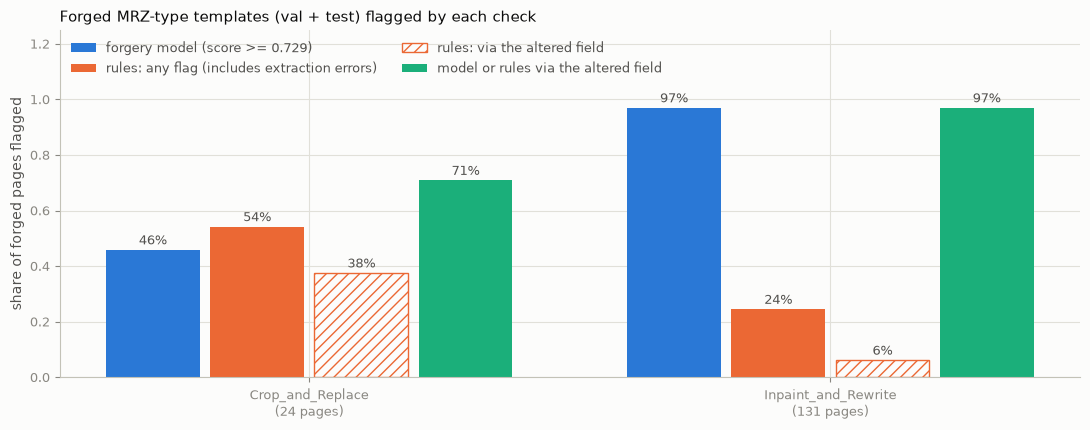

In [17]:
fig, ax = plt.subplots(figsize=(11, 4.4), dpi=100, facecolor=SURFACE)
groups = ["Crop_and_Replace", "Inpaint_and_Rewrite"]
x = np.arange(len(groups))
bars = [("model catches (>= 0.729)", BLUE, None, "forgery model (score >= 0.729)"),
        ("rules catch", ORANGE, None, "rules: any flag (includes extraction errors)"),
        ("caught via the altered field", SURFACE, ORANGE, "rules: via the altered field"),
        ("model or rules (via the altered field)", AQUA, None, "model or rules via the altered field")]
for i, (col, color, hatch_color, label) in enumerate(bars):
    values = by_ctype.loc[groups, col]
    offset = (i - 1.5) * 0.2
    ax.bar(x + offset, values, width=0.18, color=color, label=label,
           **({"hatch": "///", "edgecolor": hatch_color, "linewidth": 1} if hatch_color else {}))
    for xi, v in zip(x + offset, values):
        ax.text(xi, v + 0.02, f"{v:.0%}", ha="center", color=INK_2, fontsize=9)
ax.set_xticks(x, [f"{g}\n({int(by_ctype.loc[g, 'pages'])} pages)" for g in groups])
ax.set_ylim(0, 1.25)
style(ax, "Forged MRZ-type templates (val + test) flagged by each check")
ax.grid(color=GRID, linewidth=0.8, axis="y")
ax.set_ylabel("share of forged pages flagged")
ax.legend(frameon=False, labelcolor=INK_2, fontsize=9, loc="upper left", ncols=2)
fig.tight_layout()
fig.savefig(REPORT_DIR / "rules_vs_model_forged.png", dpi=150, facecolor=SURFACE, bbox_inches="tight")
plt.show()

<!-- id: rules_figure -->
**Figure.** For Crop_and_Replace (left), the forgery model alone flags 46 %. Adding only the rule catches explained
by the forgery (hatched, 38 %) lifts the total to 71 % (green). The solid orange bar is higher (54 %) because it
also contains flags caused by extraction errors. For Inpaint_and_Rewrite (right), the pixel model already does the
job (97 %), and the rules add nothing.

## 6 · Officer case summary

In [18]:
MOCK_CASES = {
    "clean approve": {
        "case_id": "MOCK-001", "decision": "approve",
        "document": {"doc_type": "srb_passport", "classifier_confidence": 0.998},
        "forgery": {"score": 0.08, "band": "pass (below 0.729)"},
        "face": {"score": 0.71, "threshold": 0.2597, "band": "match"},
        "extraction": {"valid": True, "fields": {"surname": "POPADIĆ", "given_names": "PRIBISLAV",
                                                 "document_number": "283430483", "expiry_date": "03.01.2031"}},
        "consistency": {"flags": [], "info": []}},
    "forgery suspected": {
        "case_id": "MOCK-002", "decision": "manual review (forgery suspected)",
        "document": {"doc_type": "lva_passport", "classifier_confidence": 0.991},
        "forgery": {"score": 0.93, "band": "forgery suspected (0.857 or higher)"},
        "face": {"score": 0.64, "threshold": 0.2597, "band": "match"},
        "extraction": {"valid": True, "fields": {"surname": "OZOLS", "given_names": "JĀNIS",
                                                 "document_number": "LV6309038"}},
        "consistency": {"flags": ["mrz_vs_surname: page 'OZOLS' vs MRZ 'ALKSNIS'"], "info": []}},
    "face mismatch": {
        "case_id": "MOCK-003", "decision": "manual review (face does not match)",
        "document": {"doc_type": "est_id", "classifier_confidence": 0.995},
        "forgery": {"score": 0.21, "band": "pass (below 0.729)"},
        "face": {"score": 0.11, "threshold": 0.2597, "band": "no match (below threshold)"},
        "extraction": {"valid": True, "fields": {"surname": "LAAR", "given_names": "AABEL",
                                                 "document_number": "AA6557729"}},
        "consistency": {"flags": [], "info": []}},
}


def numbers(text):
    return set(re.findall(r"\d+(?:\.\d+)?", text))


summaries = []
for name, case in MOCK_CASES.items():
    start = time.perf_counter()
    llm_text = extraction.summarize_case(case, ollama)
    seconds = time.perf_counter() - start
    template_text = extraction.summarize_case(case)  # no LLM: the fallback
    unsupported = numbers(llm_text) - numbers(json.dumps(case, ensure_ascii=False))  # numbers not in the input
    summaries.append({"case": name, "LLM seconds": round(seconds, 1), "numbers not in the input": sorted(unsupported) or "none"})
    print(f"=== {name} ({case['case_id']})\nLLM ({ollama.model}, {seconds:.1f} s):\n{llm_text}\n\nTemplate fallback:\n{template_text}\n")
display(pd.DataFrame(summaries))

=== clean approve (MOCK-001)
LLM (qwen2.5vl:7b, 11.4 s):
The decision is to approve the application. The document type is a SRB passport, and the classifier confidence is 0.998, indicating a high level of confidence in the document's authenticity. The forgery score is 0.08, which falls within the "pass" band (below 0.729), suggesting the document is not a forgery. The face recognition score is 0.71, which is above the threshold of 0.2597, indicating a match. The document extraction is valid, and the fields extracted are surname: POPADIĆ, given names: PRIBISLAV, document number: 283430483, and expiry date: 03.01.2031. There are no flags or inconsistencies in the consistency check. The officer should review the document for any additional discrepancies or issues that might not have been captured in the current checks.

Template fallback:
Case MOCK-001: decision approve. Document recognised as srb_passport (classifier confidence 0.998). Forgery score 0.08 (pass (below 0.729)). Face match 

=== forgery suspected (MOCK-002)
LLM (qwen2.5vl:7b, 7.1 s):
The decision for case ID MOCK-002 is a manual review due to forgery suspicion. The document type is a LVA passport with a classifier confidence of 0.991. The forgery score is 0.93, falling within the "forgery suspected" band (0.857 or higher). The face recognition score is 0.64, which is above the threshold of 0.2597, indicating a match. The document extraction is valid, with fields including surname "OZOLS," given names "JĀNIS," and document number "LV6309038." The consistency check flags a discrepancy between the MRZ surname "ALKSNIS" and the document's surname "OZOLS." The officer should review the MRZ data and the discrepancy in the surname to ensure the document's authenticity.

Template fallback:
Case MOCK-002: decision manual review (forgery suspected). Document recognised as lva_passport (classifier confidence 0.991). Forgery score 0.93 (forgery suspected (0.857 or higher)). Face match score 0.64 (match). Fields extrac

=== face mismatch (MOCK-003)
LLM (qwen2.5vl:7b, 6.3 s):
The decision for case ID MOCK-003 is a manual review due to the face not matching. The document type is an EST ID with a classifier confidence of 0.995. The forgery score is 0.21, falling within the pass band (below 0.729). The face score is 0.11, which is below the threshold of 0.2597, indicating no match. The extraction is valid, with the fields being surname "LAAR," given names "AABEL," and document number "AA6557729." There are no flags or additional information in the consistency check. The officer should review the face image and consider additional verification methods to ensure the identity is confirmed.

Template fallback:
Case MOCK-003: decision manual review (face does not match). Document recognised as est_id (classifier confidence 0.995). Forgery score 0.21 (pass (below 0.729)). Face match score 0.11 (no match (below threshold)). Fields extracted and validated. All consistency rules passed.



,case,LLM seconds,numbers not in the input
0,clean approve,11.4,none
1,forgery suspected,7.1,none
2,face mismatch,6.3,none


<!-- id: summaries -->
**Officer case summaries for three mock cases** (local qwen2.5vl:7b at temperature 0, 6-12 s each, against the
template fallback).
- **Faithful to the input:**
  - all three summaries state the decision first and go through every check with its number;
  - **no number appears that is not in the input JSON** (the automatic check in the table);
  - the forgery case quotes the MRZ surname conflict correctly.
- **One unsupported phrase:** the first summary says the classifier confidence indicates "the document's
  authenticity". The classifier only recognises the document *type*. So "use only facts present in the input" is
  followed for numbers, not perfectly for interpretation.
- **For the officer portal:** show the template text as the record of the case, and the LLM text as a readable
  summary under it.
- **The template fallback** gives the same facts in fixed sentences when no LLM is available, and is what the tests
  check.

## 7 · Saving and unloading the model

In [19]:
metrics = {
    "prompt_version": extraction.PROMPT_VERSION, "extractors": {n: e.model for n, e in EXTRACTORS.items()},
    "cloud": "run" if cloud else "skipped: no LLM_API_KEY",
    "dev": {v: summarise_run(dev_runs[v], dev_scores[v]) for v in dev_runs},
    "test": {n: summarise_run(test_runs[n], test_scores[n]) for n in test_runs},
    "test_per_field": per_field.round(4).to_dict(orient="index"),
    "test_per_doc_type": per_type.round(4).to_dict(orient="index"),
    "rules_ground_truth": rule_rates.drop(columns="level").round(4).to_dict(orient="index"),
    "rules_demoted": list(demote),
    "rules_extracted_test": extracted_rates.round(4).to_dict(orient="index"),
    "forged_mrz": {"pages": len(forged), "by_ctype": by_ctype.round(4).to_dict(orient="index"),
                   "crop_and_replace_missed_by_model": int(len(missed_cr)),
                   "of_those_caught_by_rules": int(missed_cr["rules catch"].sum())},
    "summaries": summaries,
    "peak_memory_gb_notebook": round(peak_memory_gb(), 2),
}
(REPORT_DIR / "phase5_metrics.json").write_text(json.dumps(metrics, indent=2, default=float, ensure_ascii=False))
ollama.unload()  # free the 6-8 GB of the local model now (keep_alive would otherwise hold it 10 more minutes)
time.sleep(2)
loaded = [m["name"] for m in httpx.get(f"{ollama.host}/api/ps", timeout=5).json().get("models", [])]
print(f"Ollama models still loaded: {loaded or 'none'} | memory: {memory_status()}")
print(f"notebook run time {(time.perf_counter() - notebook_start) / 60:.1f} min | peak memory of this notebook "
      f"{metrics['peak_memory_gb_notebook']} GB")
for path in sorted(REPORT_DIR.iterdir()):
    print(f"  {path.relative_to(ROOT)}  ({path.stat().st_size / 1024:.0f} KB)")

Ollama models still loaded: none | memory: swap used 13.7 GB | System-wide memory free percentage: 60%
notebook run time 0.5 min | peak memory of this notebook 0.15 GB
  reports/phase5/extraction_test_accuracy.png  (79 KB)
  reports/phase5/extraction_test_per_doc_type.csv  (1 KB)
  reports/phase5/extraction_test_per_document.csv  (68 KB)
  reports/phase5/extraction_test_per_document_field.csv  (127 KB)
  reports/phase5/extraction_test_per_field.csv  (1 KB)
  reports/phase5/extractions_dev.jsonl  (62 KB)
  reports/phase5/extractions_forged_mrz.jsonl  (193 KB)
  reports/phase5/extractions_test_genuine.jsonl  (153 KB)
  reports/phase5/field_mapping.csv  (1 KB)
  reports/phase5/forgery_v3_page_scores_valtest.csv  (85 KB)
  reports/phase5/phase5_metrics.json  (10 KB)
  reports/phase5/rules_false_flags_extracted_test.csv  (1 KB)
  reports/phase5/rules_false_flags_ground_truth.csv  (1 KB)
  reports/phase5/rules_forged_mrz_val_test.csv  (34 KB)
  reports/phase5/rules_vs_model_forged.png  (69 K

<!-- id: saved -->
**Saved and unloaded.** The model was unloaded at the end (`keep_alive` 0) and nothing stays loaded.
- **`reports/phase5/` holds:**
  - the per-document extraction results (the three `extractions_*.jsonl` caches, with raw answers, attempts,
    latency and tokens);
  - per-document field comparisons for the test set and the per-field and per-type tables;
  - the mapping table and the rule tables (ground truth, extracted genuine, forged);
  - the forgery scores, both figures, and `phase5_metrics.json`.
- **Runtime:**
  - this notebook took 0.5 min, with everything cached except the three summaries;
  - the one-time runs took 10 + 7 min (dev v1, v2), about 87 min (148 genuine test documents) and 82 min (155 forged
    documents), under heavy memory pressure;
  - the forgery scoring took 5.4 min.
- **Memory:** the notebook itself peaks at 0.16 GB; the Ollama runner used 5-8 GB (11 GB before the first unload).